# NB03 — Evaluation and cold start

**Question.** On new simulated learners, does the trained Q policy beat the rule and the fixed-level policies, does the strain penalty change behaviour,
how fast does Q learn from scratch, does a pretrained model help a new child (cold start), and does it treat beginners and advanced learners sensibly?

**Inputs.** `outputs/models/q_main.json`, `q_no_strain.json` (NB02), `rl_core`. **Outputs.** `outputs/figures/03_*.png`, `outputs/tables/03_*.csv`, `outputs/reports/03_summary.md`.
Combined mode, additions ON, familiarization sessions use the rule in every arm. Evaluation seeds ≥ 9,000,000 and different from NB02's quick check (9,000,000–9,000,099):
main evaluation 9,100,000+, cold start 9,200,000+. Learning-speed training seeds 500,000+ (< 9,000,000). Starting mastery is used only to group results.

**Disclosure.** Literature-informed synthetic data — not clinical evidence. Simulation-only; not approved for use with children.

In [1]:
import sys, json, time, copy
from pathlib import Path
T_NB = time.time()
RL_ROOT = Path.cwd().resolve().parent
for p in (RL_ROOT, RL_ROOT / "notebooks"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import rlconfig as cfg
import rl_core
from rl_core import env as E
from rl_core.env import SimConfig, run_learner, sample_learner, rule_policy, level1_policy
from rl_core.agent import QAgent, AgentPolicy, WEIGHTS

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.width", 220, "display.max_columns", 40)
sns.set_theme(style="whitegrid")
for d in (cfg.FIGURES_DIR, cfg.TABLES_DIR, cfg.REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)
save_table = lambda df, n: df.to_csv(cfg.TABLES_DIR / f"03_{n}.csv", index=False)
def save_fig(fig, n): fig.savefig(cfg.FIGURES_DIR / f"03_{n}.png", dpi=130, bbox_inches="tight")
SIM = SimConfig(growth=True, boredom=True, eta=E.ETA)

Q_MAIN, Q_NS = (QAgent.load(cfg.MODELS_DIR / f"{n}.json") for n in ("q_main", "q_no_strain"))
meta = json.loads((cfg.MODELS_DIR / "q_main.json").read_text(encoding="utf-8"))
TAU = meta["tau"]
assert meta["weights"] == WEIGHTS and TAU == 0.70
print(cfg.DISCLOSURE, "| tau =", TAU, "| Q main states:", len(Q_MAIN.Q), "| Q no-strain states:", len(Q_NS.Q))

class RuleScored(AgentPolicy):
    """The rule policy, with the same reward bookkeeping as the agent."""
    def __call__(self, obs, allowed, env): return env.rule_action()

def hold_at(L):
    def pol(obs, allowed, env):
        d = obs["difficulty"]
        if d > L and "decrease_difficulty" in allowed: return "decrease_difficulty"
        if d < L and "increase_difficulty" in allowed: return "increase_difficulty"
        return "hold"
    return pol
pm = lambda x: f"{x.mean():.4f} ± {x.std() / np.sqrt(x.count()):.4f}"
pdiff = lambda x: f"{x.mean():+.4f} ± {x.std() / np.sqrt(x.count()):.4f}"

Literature-informed synthetic data — not clinical evidence. Simulation-only; not approved for use with children. | tau = 0.7 | Q main states: 122 | Q no-strain states: 125


## 1. Main evaluation — 300 new learners × 25 sessions, five arms

rule · hold level 1 · hold level 3 (best fixed level in NB02) · Q main (greedy, frozen) · Q no-strain (greedy, frozen).
Time-in-band = share of post-familiarization decisions (3rd task on) whose first-try rate is within tau ± 0.10 = [0.60, 0.80].
Frustration and engagement are means over complete-telemetry sessions.

rule: 97s


hold L1: 116s


hold L3: 142s


Q main: 93s


Q no-strain: 87s


...

paired z (diff / SE):


,mastery_gain,first_try,time_in_band,frustration,engagement,safety_events,dropout,mean_difficulty
hold L1,-63.6,6.4,8.5,-5.6,3.2,-12.9,15.7,-69.2
hold L3,31.6,36.2,-16.8,-41.7,19.0,-11.3,-2.0,-5.5
Q main,31.3,24.5,-4.7,-11.0,15.1,-9.9,-6.4,-3.7
Q no-strain,5.5,37.3,-7.5,9.0,15.8,-13.9,11.0,-34.5


Q main vs the best fixed level (hold L3), paired:


,mastery_gain,first_try,time_in_band,frustration,engagement,safety_events,dropout,mean_difficulty
Q main - hold L3,+0.0021 ± 0.0030,-0.0299 ± 0.0012,+0.0554 ± 0.0031,+0.0712 ± 0.0023,-0.0017 ± 0.0003,+0.0103 ± 0.0068,-0.0160 ± 0.0052,+0.0336 ± 0.0196
z,0.7,-25.8,17.7,31.3,-5.4,1.5,-3.1,1.7


frustration/engagement n (learners with >=1 complete session): 300 of 300


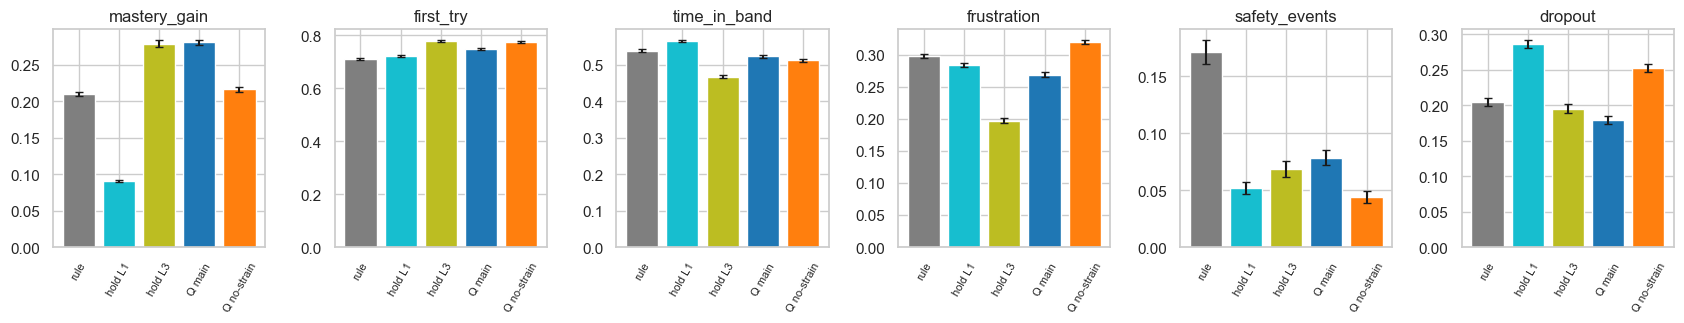

In [2]:
def run_arm(make, learners, seed0, n_sessions=25):
    rows = []
    for i, L in enumerate(learners):
        d, s = run_learner(make(i), L, n_sessions=n_sessions, seed=seed0 + i, sim=SIM)
        a = d[(d.phase != "familiarization") & (d.tasks_done >= 3)]
        rows.append(dict(mastery_gain=s.mastery_end.iloc[-1] - s.mastery_start.iloc[0], first_try=s.first_try_rate.mean(),
                         time_in_band=((a.first_try - TAU).abs() <= 0.10 + 1e-9).mean(), frustration=s.frustration_index.mean(),
                         engagement=s.engagement_score.mean(), safety_events=s.safety_override_count.mean(), dropout=s.dropout.mean(),
                         mean_difficulty=s.mean_difficulty.mean(), strain=a.strain.mean(),
                         start_mastery=float(np.mean(list(L["mastery"].values())))))
    return pd.DataFrame(rows)

MAIN_SEED0 = 9_100_000
MAIN = [sample_learner(MAIN_SEED0 + i) for i in range(300)]
ARMS = {"rule": lambda i: rule_policy, "hold L1": lambda i: level1_policy, "hold L3": lambda i: hold_at(3),
        "Q main": lambda i: AgentPolicy(Q_MAIN.greedy(), TAU, WEIGHTS, seed=i, learn=False),
        "Q no-strain": lambda i: AgentPolicy(Q_NS.greedy(), TAU, WEIGHTS, seed=i, learn=False)}
RES = {}
for name, make in ARMS.items():
    t = time.time(); RES[name] = run_arm(make, MAIN, MAIN_SEED0); print(f"{name}: {time.time() - t:.0f}s", flush=True)

METRICS = ["mastery_gain", "first_try", "time_in_band", "frustration", "engagement", "safety_events", "dropout", "mean_difficulty"]
T1 = pd.DataFrame({a: RES[a][METRICS].apply(pm) for a in RES}).T
display(T1); save_table(T1.reset_index().rename(columns={"index": "arm"}), "main_table")
PD = pd.DataFrame({a: (RES[a][METRICS] - RES["rule"][METRICS]).apply(pdiff) for a in RES if a != "rule"}).T
print("paired difference vs rule (same learners and seeds), mean ± SE:"); display(PD); save_table(PD.reset_index().rename(columns={"index": "arm"}), "main_paired_vs_rule")
z = pd.DataFrame({a: (RES[a][METRICS] - RES["rule"][METRICS]).apply(lambda x: x.mean() / (x.std() / np.sqrt(x.count()))) for a in RES if a != "rule"}).T
print("paired z (diff / SE):"); display(z.round(1))
d3 = RES["Q main"][METRICS] - RES["hold L3"][METRICS]
P3 = pd.DataFrame({"Q main - hold L3": d3.apply(pdiff), "z": d3.apply(lambda x: x.mean() / (x.std() / np.sqrt(x.count()))).round(1)}).T
print("Q main vs the best fixed level (hold L3), paired:"); display(P3); save_table(P3.reset_index().rename(columns={"index": "row"}), "main_q_vs_hold3")
pd.concat({a_: RES[a_] for a_ in RES}, names=["arm", "learner"]).reset_index(level=0).to_csv(cfg.TABLES_DIR / "03_main_per_learner.csv", index=False)
print("frustration/engagement n (learners with >=1 complete session):", RES["rule"].frustration.count(), "of 300")

show = ["mastery_gain", "first_try", "time_in_band", "frustration", "safety_events", "dropout"]
colors = dict(zip(ARMS, ["tab:gray", "tab:cyan", "tab:olive", "tab:blue", "tab:orange"]))
fig, ax = plt.subplots(1, 6, figsize=(17, 3.4))
for a_, m in zip(ax, show):
    mu = [RES[k][m].mean() for k in ARMS]; se = [RES[k][m].std() / np.sqrt(RES[k][m].count()) for k in ARMS]
    a_.bar(range(5), mu, yerr=se, color=[colors[k] for k in ARMS], capsize=3); a_.set_title(m); a_.set_xticks(range(5)); a_.set_xticklabels(list(ARMS), rotation=60, fontsize=8)
fig.tight_layout(); save_fig(fig, "main_bars"); plt.show()

### Findings — step 1

300 new learners × 25 sessions (seeds 9,100,000+), mean ± SE; familiarization uses the rule in every arm.

| arm | mastery gain | first-try | time-in-band | frustration | engagement | safety / session | dropout | mean difficulty |
|---|---|---|---|---|---|---|---|---|
| rule | 0.2097 ± 0.0030 | 0.710 | 0.539 | 0.298 | 0.699 | 0.172 | 0.204 | 2.64 |
| hold L1 | 0.0901 ± 0.0013 | 0.723 | **0.565** | 0.284 | 0.701 | **0.052** | 0.286 | 1.20 |
| hold L3 | 0.2789 ± 0.0046 | **0.779** | 0.467 | **0.197** | **0.706** | 0.068 | 0.195 | 2.54 |
| **Q main** | **0.2810 ± 0.0034** | 0.749 | 0.522 | 0.269 | 0.704 | 0.079 | **0.179** | 2.57 |
| Q no-strain | 0.2166 ± 0.0036 | 0.773 | 0.512 | 0.320 | 0.705 | 0.044 | 0.252 | 1.95 |

Paired vs rule: **Q main** mastery gain **+0.0713 ± 0.0023** (z 31), first-try +0.040, frustration −0.029 (z −11), safety events −0.093 (z −10), dropout −0.025 (z −6), time-in-band −0.016 (z −4.7, slightly *worse*), mean difficulty −0.06.

- **Q main clearly beats the rule** on mastery gain (+34 % relative), frustration, safety and dropout. It is not better on time-in-band (0.522 vs 0.539), the one metric it was not built for.
- **Hold level 3 is a strong baseline.** Paired Q main − hold L3: mastery gain +0.0021 ± 0.0030 (z 0.7, a tie), dropout −0.016 ± 0.005 (z −3.1), safety +0.010 ± 0.007 (n.s.); but hold L3 has higher first-try (+0.030 for it) and **lower frustration (0.197 vs 0.269, z 31)**, while Q has better time-in-band (+0.055). So in this simulator the learned policy matches the best fixed level on learning and does not beat it on comfort; its edge is over the rule and over level 1. Hold L1 is again worst on learning (gain 0.090, dropout 0.286).
- Frustration / engagement means use all 300 learners (each has at least one complete-telemetry session). Engagement hardly differs between arms (0.699–0.706).

## 2. Frustration ablation — Q main vs Q no-strain

Paired on the same 300 learners and seeds (strain = mean rolling strain at post-familiarization decisions).

In [3]:
AB = ["frustration", "strain", "safety_events", "dropout", "mastery_gain", "mean_difficulty", "first_try", "time_in_band"]
dd = RES["Q main"][AB] - RES["Q no-strain"][AB]
T2 = pd.DataFrame({"Q main": RES["Q main"][AB].apply(pm), "Q no-strain": RES["Q no-strain"][AB].apply(pm),
                   "main - no-strain": dd.apply(pdiff), "z": dd.apply(lambda x: x.mean() / (x.std() / np.sqrt(x.count()))).round(2)})
display(T2); save_table(T2.reset_index().rename(columns={"index": "metric"}), "ablation_paired")
ag, an = Q_MAIN.greedy(), Q_NS.greedy()
common = [s for s in Q_MAIN.Q if s in Q_NS.Q and Q_MAIN.visits.get(s, 0) >= 20 and Q_NS.visits.get(s, 0) >= 20]
agree = np.mean([ag._best(s, list(E.ACTIONS)) == an._best(s, list(E.ACTIONS)) for s in common])
hi = [s for s in common if s[2] >= 1]
agree_hi = np.mean([ag._best(s, list(E.ACTIONS)) == an._best(s, list(E.ACTIONS)) for s in hi])
print(f"greedy actions agree in {agree:.1%} of {len(common)} well-visited states; in the {len(hi)} states with strain mid/high: {agree_hi:.1%}")

,Q main,Q no-strain,main - no-strain,z
frustration,0.2685 ± 0.0040,0.3199 ± 0.0032,-0.0515 ± 0.0022,-23.17
strain,0.1347 ± 0.0019,0.1188 ± 0.0019,+0.0160 ± 0.0006,25.39
safety_events,0.0787 ± 0.0068,0.0439 ± 0.0054,+0.0348 ± 0.0054,6.49
dropout,0.1791 ± 0.0057,0.2519 ± 0.0060,-0.0728 ± 0.0052,-13.98
mastery_gain,0.2810 ± 0.0034,0.2166 ± 0.0036,+0.0644 ± 0.0025,25.82
mean_difficulty,2.5748 ± 0.0264,1.9496 ± 0.0063,+0.6252 ± 0.0229,27.36
first_try,0.7494 ± 0.0037,0.7734 ± 0.0037,-0.0240 ± 0.0009,-25.74
time_in_band,0.5223 ± 0.0038,0.5119 ± 0.0041,+0.0104 ± 0.0025,4.18


greedy actions agree in 63.9% of 97 well-visited states; in the 60 states with strain mid/high: 63.3%


### Findings — step 2

Q main − Q no-strain, paired on the same 300 learners:

| metric | Q main | Q no-strain | main − no-strain | z |
|---|---|---|---|---|
| frustration index | 0.269 | 0.320 | −0.0515 ± 0.0022 | −23 |
| mean rolling strain | 0.135 | 0.119 | +0.0160 ± 0.0006 | +25 |
| safety events / session | 0.079 | 0.044 | +0.035 ± 0.005 | +6.5 |
| dropout / session | 0.179 | 0.252 | −0.073 ± 0.005 | −14 |
| mastery gain | 0.281 | 0.217 | +0.064 ± 0.003 | +26 |
| mean difficulty | 2.57 | 1.95 | +0.63 ± 0.02 | +27 |
| first-try | 0.749 | 0.773 | −0.024 | −26 |

**Verdict: yes, the strain penalty changes behaviour, but not in the direction the label suggests.** In NB02's training statistics the two agents looked alike (exploring action mix), but the *greedy* policies differ: they pick the same action in only 63.9 % of well-visited states. Without the strain penalty the agent sits at easier levels (mean difficulty 1.95 vs 2.57), which gives fewer safety events (0.044 vs 0.079) and slightly lower measured strain at decisions (0.119 vs 0.135) — the comfort the penalty was meant to buy — yet it has **a higher frustration index (0.320 vs 0.269), more dropout and less mastery gain**. So the penalty did not produce a lower-strain policy; the version with the penalty is better on frustration index, dropout and learning, and only worse on safety events and rolling strain. I have no verified mechanism for the frustration result: the frustration index is a session-level composite (not the rolling strain used in the reward), and the easy-level policy probably loses through boredom-driven dropout and the learner-state rules. That is a hypothesis, not tested here.

## 3. Learning speed from scratch

A fresh Q agent (eps 0.10, alpha 0.10) learns online across 300 new learners × 25 sessions (seeds 500,000+). Mean reward per decision per block of 5 learners;
the rule's mean reward on the same learners is the reference. (The curve includes exploration, so it sits below the greedy policy.)

rule mean reward on these learners: 0.4605
Q (exploring) mean reward: learners 1-20 0.4918 | 21-50 0.5064 | 51-100 0.5113 | 101-200 0.5120 | 201-300 0.5072
rolling-20-learner mean first >= rule mean at learner 20; first within 0.01 of the final plateau (0.5072) at learner 25; plateau check: learners 101-200 0.5120 vs 201-300 0.5072


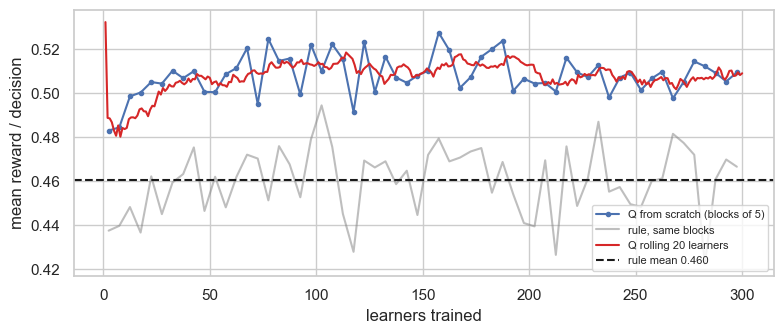

In [4]:
LS = [sample_learner(500_000 + i) for i in range(300)]
agent = QAgent(); pol = AgentPolicy(agent, TAU, WEIGHTS, seed=1)
agent_rows, rule_rows = [], []
for i, L in enumerate(LS):
    pol.rewards.clear(); run_learner(pol, L, 25, seed=500_000 + i, sim=SIM)
    agent_rows.append((np.sum(pol.rewards), len(pol.rewards)))
    rp = RuleScored(QAgent(), TAU, WEIGHTS); run_learner(rp, L, 25, seed=500_000 + i, sim=SIM)
    rule_rows.append((np.sum(rp.rewards), len(rp.rewards)))
A, R = np.array(agent_rows), np.array(rule_rows)
rule_mean = R[:, 0].sum() / R[:, 1].sum()
blk = lambda X, k: np.array([X[i:i + k, 0].sum() / X[i:i + k, 1].sum() for i in range(0, len(X), k)])
ba, br = blk(A, 5), blk(R, 5)
roll = lambda X, k: np.array([X[max(0, i - k + 1):i + 1, 0].sum() / X[max(0, i - k + 1):i + 1, 1].sum() for i in range(len(X))])
r20 = roll(A, 20)
reach = next((i + 1 for i in range(19, 300) if r20[i] >= rule_mean), None)
plateau = A[-100:, 0].sum() / A[-100:, 1].sum(); prev = A[-200:-100, 0].sum() / A[-200:-100, 1].sum()
within = next((i + 1 for i in range(19, 300) if abs(r20[i] - plateau) <= 0.01), None)
print(f"rule mean reward on these learners: {rule_mean:.4f}")
print(f"Q (exploring) mean reward: learners 1-20 {A[:20, 0].sum() / A[:20, 1].sum():.4f} | 21-50 {A[20:50, 0].sum() / A[20:50, 1].sum():.4f} | 51-100 {A[50:100, 0].sum() / A[50:100, 1].sum():.4f} | 101-200 {A[100:200, 0].sum() / A[100:200, 1].sum():.4f} | 201-300 {plateau:.4f}")
print(f"rolling-20-learner mean first >= rule mean at learner {reach}; first within 0.01 of the final plateau ({plateau:.4f}) at learner {within}; plateau check: learners 101-200 {prev:.4f} vs 201-300 {plateau:.4f}")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(len(ba)) * 5 + 2.5, ba, "o-", ms=3, label="Q from scratch (blocks of 5)"); ax.plot(np.arange(len(br)) * 5 + 2.5, br, color="tab:gray", alpha=.5, label="rule, same blocks")
ax.plot(np.arange(300) + 1, r20, color="tab:red", lw=1.5, label="Q rolling 20 learners"); ax.axhline(rule_mean, color="k", ls="--", label=f"rule mean {rule_mean:.3f}")
ax.set_xlabel("learners trained"); ax.set_ylabel("mean reward / decision"); ax.legend(fontsize=8); fig.tight_layout(); save_fig(fig, "learning_speed"); plt.show()
save_table(pd.DataFrame({"block_start": np.arange(len(ba)) * 5 + 1, "q_reward": ba, "rule_reward": br}), "learning_speed")

### Findings — step 3

Fresh agent (eps 0.10, alpha 0.10) learning online over 300 learners × 25 sessions (seeds 500,000+); the rule's mean reward on the same learners is **0.4605**.

- **It is at the rule's level almost immediately.** The first block of 5 learners already gives 0.483 vs the rule's 0.438; the first 20 learners average 0.4918 (the rolling-20 curve first exceeds the rule at learner 20, the earliest it can be computed).
- **Plateau at ≈ 0.51:** learners 21–50 0.5064, 51–100 0.5113, 101–200 0.5120, 201–300 0.5072 (within 0.01 of the final plateau from learner ≈ 25). Learners 101–200 vs 201–300 differ by 0.005, so there is no further trend.
- This is the exploring agent's reward (10 % random actions), so it sits below the frozen greedy policy. As in NB02, reward is a weak signal: it is above the rule from the first block, whereas mastery gain tells a different story (step 4: a per-child scratch agent has *lower* mastery gain than the rule).

## 4. Cold start — one agent per child, kept across that child's 25 sessions

100 new learners (seeds 9,200,000+). (a) rule · (b) scratch: empty Q, eps 0.10, alpha 0.10 · (c) pretrained frozen: greedy q_main · (d) pretrained + fine-tune: a copy of q_main
that keeps learning with alpha 0.05, eps 0.05. Sessions 1–W (W = 2 or 3) are familiarization, identical in every arm; reward is only defined from the first acting session.

(a) rule: 25s


(b) scratch: 28s


(c) pretrained frozen: 27s


(d) pretrained + fine-tune: 29s


C:\Users\Yasindu\AppData\Local\Temp\ipykernel_28872\2065017118.py:22: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(X, 0); se = np.nanstd(X, 0) / np.sqrt(np.sum(~np.isnan(X), 0))
C:\Users\Yasindu\.conda\envs\c-rl\lib\site-packages\numpy\lib\_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


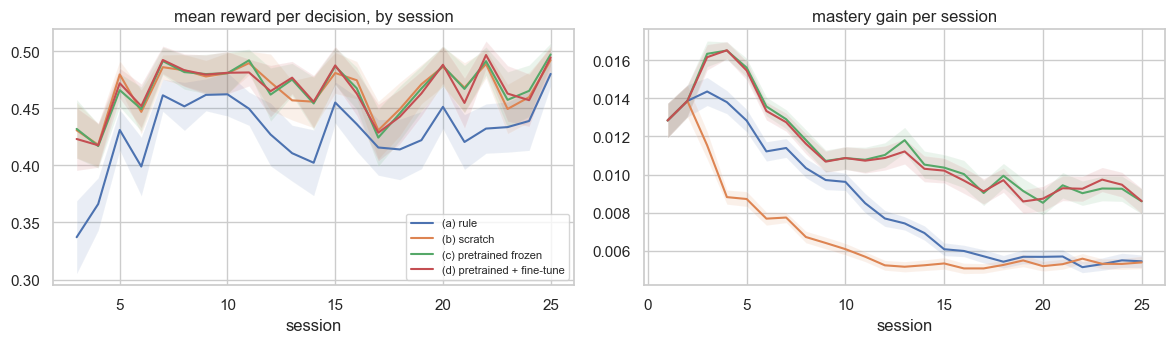

arm,(a) rule,(b) scratch,(c) pretrained frozen,(d) pretrained + fine-tune
reward 1-5,0.3844 ± 0.0125,0.4422 ± 0.0106,0.4369 ± 0.0121,0.4387 ± 0.0120
reward 6-10,0.4485 ± 0.0089,0.4754 ± 0.0076,0.4776 ± 0.0078,0.4786 ± 0.0078
reward 21-25,0.4418 ± 0.0084,0.4710 ± 0.0077,0.4760 ± 0.0084,0.4736 ± 0.0087
gain/session 1-5,0.0135 ± 0.0004,0.0112 ± 0.0004,0.0150 ± 0.0004,0.0150 ± 0.0004
gain/session 6-10,0.0105 ± 0.0003,0.0069 ± 0.0002,0.0120 ± 0.0003,0.0119 ± 0.0003
gain/session 21-25,0.0054 ± 0.0002,0.0054 ± 0.0002,0.0091 ± 0.0004,0.0093 ± 0.0004


,1-5,6-10,21-25
(d) - (b) reward,-0.0036 ± 0.0086 (z -0.4),+0.0032 ± 0.0059 (z +0.5),+0.0025 ± 0.0079 (z +0.3)
(d) - (c) reward,+0.0018 ± 0.0037 (z +0.5),+0.0010 ± 0.0008 (z +1.2),-0.0025 ± 0.0033 (z -0.7)
(c) - (b) reward,-0.0054 ± 0.0090 (z -0.6),+0.0023 ± 0.0059 (z +0.4),+0.0050 ± 0.0076 (z +0.7)
(d) - (b) gain,+0.0038 ± 0.0002 (z +23.3),+0.0049 ± 0.0003 (z +15.7),+0.0039 ± 0.0004 (z +9.7)
(d) - (c) gain,-0.0001 ± 0.0000 (z -1.6),-0.0001 ± 0.0001 (z -2.5),+0.0002 ± 0.0002 (z +0.8)
(d) - (a) gain,+0.0014 ± 0.0002 (z +7.4),+0.0014 ± 0.0004 (z +3.8),+0.0039 ± 0.0004 (z +9.6)


whole-run mastery gain (sum over 25 sessions), mean: {'(a) rule': 0.2121, '(b) scratch': 0.1699, '(c) pretrained frozen': 0.2818, '(d) pretrained + fine-tune': 0.2796}


In [5]:
CS_SEED0 = 9_200_000
CS = [sample_learner(CS_SEED0 + i) for i in range(100)]
def tuned():
    a = copy.deepcopy(Q_MAIN); a.epsilon, a.alpha = 0.05, 0.05; return a
CARMS = {"(a) rule": lambda i: RuleScored(QAgent(), TAU, WEIGHTS, seed=i, learn=False),
         "(b) scratch": lambda i: AgentPolicy(QAgent(epsilon=0.10, alpha=0.10), TAU, WEIGHTS, seed=i),
         "(c) pretrained frozen": lambda i: AgentPolicy(Q_MAIN.greedy(), TAU, WEIGHTS, seed=i, learn=False),
         "(d) pretrained + fine-tune": lambda i: AgentPolicy(tuned(), TAU, WEIGHTS, seed=i)}
REW, GAIN = {}, {}
for name, make in CARMS.items():
    r = np.full((100, 25), np.nan); g = np.zeros((100, 25)); t = time.time()
    for i, L in enumerate(CS):
        pol = make(i); _, s = run_learner(pol, L, 25, seed=CS_SEED0 + i, sim=SIM)
        g[i] = s.mastery_gain.values
        lg = pd.DataFrame(pol.log, columns=["n", "r"]).groupby("n").r.mean()
        r[i, lg.index.values - 1] = lg.values
    REW[name], GAIN[name] = r, g; print(f"{name}: {time.time() - t:.0f}s", flush=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for name in CARMS:
    for a_, X, ttl in ((ax[0], REW[name], "mean reward per decision, by session"), (ax[1], GAIN[name], "mastery gain per session")):
        mu = np.nanmean(X, 0); se = np.nanstd(X, 0) / np.sqrt(np.sum(~np.isnan(X), 0))
        a_.plot(np.arange(1, 26), mu, label=name); a_.fill_between(np.arange(1, 26), mu - se, mu + se, alpha=.12); a_.set_title(ttl); a_.set_xlabel("session")
ax[0].legend(fontsize=8); fig.tight_layout(); save_fig(fig, "cold_start"); plt.show()

seg = lambda X, a, b: np.nanmean(X[:, a - 1:b], axis=1)
SEGS = {"1-5": (1, 5), "6-10": (6, 10), "21-25": (21, 25)}
rows = []
for name in CARMS:
    rows.append({"arm": name, **{f"reward {k}": pm(pd.Series(seg(REW[name], *v))) for k, v in SEGS.items()},
                 **{f"gain/session {k}": pm(pd.Series(seg(GAIN[name], *v))) for k, v in SEGS.items()}})
T4 = pd.DataFrame(rows).set_index("arm"); display(T4.T); save_table(T4.reset_index(), "cold_start_table")
def paired(x, y, key=None):
    out = {}
    for k, v in SEGS.items():
        d = pd.Series(seg(x, *v) - seg(y, *v)); out[k] = pdiff(d) + f" (z {d.mean() / (d.std() / np.sqrt(d.count())):+.1f})"
    return out
PR = pd.DataFrame({"(d) - (b) reward": paired(REW["(d) pretrained + fine-tune"], REW["(b) scratch"], None),
                   "(d) - (c) reward": paired(REW["(d) pretrained + fine-tune"], REW["(c) pretrained frozen"], None),
                   "(c) - (b) reward": paired(REW["(c) pretrained frozen"], REW["(b) scratch"], None),
                   "(d) - (b) gain": paired(GAIN["(d) pretrained + fine-tune"], GAIN["(b) scratch"], None),
                   "(d) - (c) gain": paired(GAIN["(d) pretrained + fine-tune"], GAIN["(c) pretrained frozen"], None),
                   "(d) - (a) gain": paired(GAIN["(d) pretrained + fine-tune"], GAIN["(a) rule"], None)})
display(PR.T); save_table(PR.T.reset_index().rename(columns={"index": "paired"}), "cold_start_paired")
print("whole-run mastery gain (sum over 25 sessions), mean:", {k: round(float(v.sum(1).mean()), 4) for k, v in GAIN.items()})

### Findings — step 4

100 new learners × 25 sessions (seeds 9,200,000+), one agent per child; sessions 1–W (W = 2 or 3) are familiarization, identical in every arm.

| arm | reward 1–5 | reward 6–10 | reward 21–25 | gain/session 1–5 | 6–10 | 21–25 | whole-run gain |
|---|---|---|---|---|---|---|---|
| (a) rule | 0.384 ± 0.013 | 0.449 | 0.442 | 0.0135 | 0.0105 | 0.0054 | 0.212 |
| (b) scratch | 0.442 ± 0.011 | 0.475 | 0.471 | 0.0112 | 0.0069 | 0.0054 | 0.170 |
| (c) pretrained frozen | 0.437 ± 0.012 | 0.478 | 0.476 | 0.0150 | 0.0120 | 0.0091 | 0.282 |
| (d) pretrained + fine-tune | 0.439 ± 0.012 | 0.479 | 0.474 | 0.0150 | 0.0119 | 0.0093 | 0.280 |

- **Does (d) beat (b) early on?** On reward, **no**: (d) − (b) = −0.004 ± 0.009 in sessions 1–5 and +0.003 ± 0.006 in 6–10 (z −0.4 / +0.5); the scratch agent already earns the same reward. On **mastery gain, yes, clearly**: +0.0038 ± 0.0002 per session in sessions 1–5 (z 23), +0.0049 in 6–10, +0.0039 in 21–25 (z 10). A scratch agent learns a reward-efficient policy that teaches *less*: its whole-run gain (0.170) is below even the rule (0.212), while the pretrained arms reach 0.28.
- **Does (d) improve on (c) by the end?** **No.** (d) − (c) reward at sessions 21–25 = −0.003 ± 0.003 (z −0.7); gain/session +0.0002 ± 0.0002 (z 0.8); whole-run gain 0.280 vs 0.282. Fine-tuning with alpha 0.05 adds nothing measurable over the frozen pretrained model in 25 sessions.
- In all arms the gain per session falls over the 25 sessions (mastery saturates in the simulator); (c) and (d) keep a higher gain at 21–25 (0.009 vs 0.005 for rule and scratch).
- Reward in sessions 1–5 is averaged over acting sessions only (sessions after familiarization).

## 5. By learner level

Terciles of starting mean mastery over the 300 main-evaluation learners (grouping only; no policy sees it). Q main vs rule, paired within tercile.

In [6]:
sm = RES["rule"].start_mastery
cuts = sm.quantile([1 / 3, 2 / 3]).values
grp = pd.cut(sm, [-1, cuts[0], cuts[1], 2], labels=["beginner", "middle", "advanced"])
print("tercile cut points (mean-7 starting mastery):", np.round(cuts, 3), "| sizes:", grp.value_counts().to_dict())
TM = ["mastery_gain", "mean_difficulty", "safety_events", "dropout", "first_try", "frustration"]
rows = []
for g in ["beginner", "middle", "advanced"]:
    m = (grp == g).values
    for a in ("rule", "Q main"):
        rows.append({"tercile": g, "arm": a, **{k: pm(RES[a].loc[m, k]) for k in TM}})
    d = RES["Q main"].loc[m, TM] - RES["rule"].loc[m, TM]
    rows.append({"tercile": g, "arm": "Q - rule (paired)", **{k: pdiff(d[k]) for k in TM}})
T5 = pd.DataFrame(rows); display(T5); save_table(T5, "by_tercile")
start = RES["rule"].groupby(grp, observed=True).start_mastery.mean().round(3).to_dict(); print("mean starting mastery by tercile:", start)

tercile cut points (mean-7 starting mastery): [0.233 0.323] | sizes: {'beginner': 100, 'middle': 100, 'advanced': 100}


,tercile,arm,mastery_gain,mean_difficulty,safety_events,dropout,first_try,frustration
0,beginner,rule,0.2534 ± 0.0030,2.4053 ± 0.0239,0.2112 ± 0.0189,0.1736 ± 0.0086,0.6759 ± 0.0045,0.3290 ± 0.0045
1,beginner,Q main,0.3154 ± 0.0046,2.3523 ± 0.0269,0.1012 ± 0.0129,0.1508 ± 0.0082,0.7068 ± 0.0046,0.2991 ± 0.0058
2,beginner,Q - rule (paired),+0.0620 ± 0.0038,-0.0530 ± 0.0204,-0.1100 ± 0.0171,-0.0228 ± 0.0054,+0.0309 ± 0.0025,-0.0299 ± 0.0047
3,middle,rule,0.2145 ± 0.0034,2.6566 ± 0.0361,0.1896 ± 0.0198,0.1960 ± 0.0076,0.7023 ± 0.0049,0.2978 ± 0.0055
4,middle,Q main,0.2888 ± 0.0050,2.5680 ± 0.0383,0.0784 ± 0.0118,0.1708 ± 0.0084,0.7430 ± 0.0059,0.2692 ± 0.0067
5,middle,Q - rule (paired),+0.0743 ± 0.0041,-0.0885 ± 0.0291,-0.1112 ± 0.0169,-0.0252 ± 0.0061,+0.0407 ± 0.0028,-0.0287 ± 0.0046
6,advanced,rule,0.1612 ± 0.0040,2.8470 ± 0.0440,0.1136 ± 0.0154,0.2432 ± 0.0106,0.7507 ± 0.0051,0.2660 ± 0.0063
7,advanced,Q main,0.2388 ± 0.0052,2.8042 ± 0.0558,0.0564 ± 0.0101,0.2156 ± 0.0115,0.7984 ± 0.0053,0.2371 ± 0.0071
8,advanced,Q - rule (paired),+0.0777 ± 0.0038,-0.0429 ± 0.0348,-0.0572 ± 0.0139,-0.0276 ± 0.0085,+0.0478 ± 0.0029,-0.0289 ± 0.0044


mean starting mastery by tercile: {'beginner': 0.198, 'middle': 0.277, 'advanced': 0.382}


### Findings — step 5

Terciles of starting mean mastery (cut points 0.233 / 0.323; means 0.198 / 0.277 / 0.382), 100 learners each; Q main − rule paired:

| tercile | mastery gain | mean difficulty | safety events | dropout | first-try |
|---|---|---|---|---|---|
| beginner | +0.062 ± 0.004 | −0.053 ± 0.020 | −0.110 ± 0.017 | −0.023 ± 0.005 | +0.031 |
| middle | +0.074 ± 0.004 | −0.089 ± 0.029 | −0.111 ± 0.017 | −0.025 ± 0.006 | +0.041 |
| advanced | +0.078 ± 0.004 | −0.043 ± 0.035 | −0.057 ± 0.014 | −0.028 ± 0.009 | +0.048 |

- Q improves mastery gain in **every** tercile (advanced most, +0.078 on a rule base of 0.161) and reduces safety events in all three.
- **No sign that Q pushes advanced learners down:** their difficulty difference is −0.043 ± 0.035 (not significant); Q's mean difficulty is 2.80 for advanced vs 2.35 for beginners, so it still scales difficulty with level.
- **No sign that it overloads beginners:** their safety events fall by half (0.211 → 0.101) and dropout falls (0.174 → 0.151), with difficulty slightly lower (−0.053 ± 0.020).
- Caveat: the starting-mastery range is narrow (about 0.16–0.51), so "advanced" here is not truly advanced.

## 6. Summary

See the final Findings cell and `outputs/reports/03_summary.md`.

In [7]:
print(f"notebook run time: {(time.time() - T_NB) / 60:.1f} min")

notebook run time: 24.9 min


### Findings — summary

- **Built:** a step-wise Component C environment that reproduces the generator exactly (360 / 360 decisions identical) with two simulator additions (mastery growth, boredom dropout), and a 135-state tabular Q-learning agent that sees only the observation dict. Trained on 3,000 simulated learners; the strain ablation is a second model.
- **Main result (300 new learners × 25 sessions):** Q main vs rule: mastery gain 0.281 vs 0.210 (+0.071 ± 0.002), frustration 0.269 vs 0.298, safety events 0.079 vs 0.172, dropout 0.179 vs 0.204; time-in-band is slightly worse (0.522 vs 0.539). The best fixed level (hold L3) ties Q on mastery gain (+0.002 ± 0.003) and has lower frustration (0.197), so the learned policy mainly rediscovers a good level; it does not beat it.
- **Ablation:** the strain penalty changes the greedy policy (agreement 64 %), but the no-strain agent is *worse* on frustration (0.320 vs 0.269), dropout and learning, and better only on safety events and rolling strain.
- **Learning speed:** from scratch the agent is above the rule's reward within the first 5 learners and plateaus at ≈ 0.51 by learner ≈ 25.
- **Cold start:** the pretrained model gives the large gain (whole-run mastery gain 0.280–0.282 vs 0.170 scratch vs 0.212 rule); fine-tuning adds nothing over the frozen model, and a scratch per-child agent learns less than the rule even though its reward is as high.
- **By level:** Q helps beginner, middle and advanced learners alike (gain +0.062 / +0.074 / +0.078) without pushing advanced learners down or overloading beginners.
- **Limitations:** synthetic data; the simulator additions are assumptions (only eta is fitted); tau is derived from the simulator; c_only not evaluated (only levels 1–2 reachable); per-child learning is simulation-only and needs ethics approval before use with children.

---
_Literature-informed synthetic data — not clinical evidence. Simulation-only; not approved for use with children._

## 7. Why does frustration go up without the strain penalty?

`frustration_index` (C-COMP-v1) = 0.25·error_run + 0.20·excess_attempts + 0.15·inactivity + 0.15·floor_hits + 0.15·quit_after_error + 0.10·safety_override.
The per-component values are not kept by `run_learner`, so the five arms of step 1 are re-run on the same 300 learners and seeds with a capture wrapper around the generator's
`compute_frustration` (patched inside this notebook only; `rl_core` is unchanged). The weighted components are averaged over each learner's complete-telemetry sessions, so they add up to the
step-1 frustration value (asserted). Hypothesis to test: `floor_hits`.

rule: 709s


hold L1: 80s


hold L3: 95s


Q main: 90s


Q no-strain: 96s


...

,error_run,excess_attempts,inactivity,floor_hits,quit_after_error,safety_override,total
rule,0.1084 ± 0.0011,0.0343 ± 0.0005,0.0378 ± 0.0007,0.0369 ± 0.0011,0.0752 ± 0.0012,0.0050 ± 0.0004,0.2976 ± 0.0035
hold L1,0.0938 ± 0.0012,0.0299 ± 0.0006,0.0415 ± 0.0008,0.0488 ± 0.0004,0.0686 ± 0.0017,0.0016 ± 0.0002,0.2842 ± 0.0035
hold L3,0.0763 ± 0.0012,0.0230 ± 0.0005,0.0389 ± 0.0008,0.0043 ± 0.0004,0.0529 ± 0.0015,0.0018 ± 0.0002,0.1973 ± 0.0034
Q main,0.0882 ± 0.0012,0.0265 ± 0.0005,0.0384 ± 0.0007,0.0513 ± 0.0012,0.0621 ± 0.0015,0.0021 ± 0.0003,0.2685 ± 0.0040
Q no-strain,0.0801 ± 0.0011,0.0235 ± 0.0005,0.0405 ± 0.0008,0.1196 ± 0.0008,0.0549 ± 0.0015,0.0013 ± 0.0002,0.3199 ± 0.0032


raw (unweighted) component means, share of sessions with a floor hit, share of post-familiarization decisions at level 1:


,error_run_raw,excess_attempts_raw,inactivity_raw,floor_hits_raw,quit_after_error_raw,safety_override_raw,floor_session_share,share_decisions_at_L1
rule,0.434,0.171,0.252,0.246,0.502,0.050,0.300,0.082
hold L1,0.375,0.149,0.277,0.326,0.457,0.016,0.921,0.885
hold L3,0.305,0.115,0.259,0.029,0.352,0.018,0.035,0.006
Q main,0.353,0.132,0.256,0.342,0.414,0.021,0.415,0.130
Q no-strain,0.320,0.118,0.270,0.798,0.366,0.013,0.875,0.279


paired differences (weighted components), Q no-strain - Q main:


,no-strain - main,z,share of the gap
error_run,-0.0080 ± 0.0007,-11.4,-0.16
excess_attempts,-0.0030 ± 0.0002,-14.1,-0.06
inactivity,+0.0021 ± 0.0003,6.2,0.04
floor_hits,+0.0684 ± 0.0013,52.8,1.33
quit_after_error,-0.0072 ± 0.0009,-8.4,-0.14
safety_override,-0.0008 ± 0.0002,-3.6,-0.02
total,+0.0515 ± 0.0022,23.2,1.00


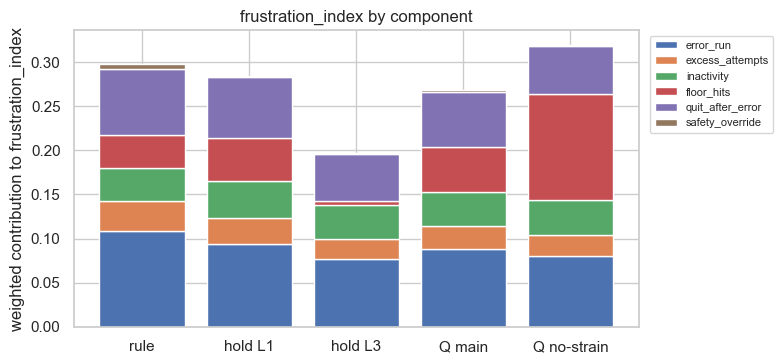

In [8]:
COMP = ["error_run", "excess_attempts", "inactivity", "floor_hits", "quit_after_error", "safety_override"]
WT = dict(zip(COMP, [0.25, 0.20, 0.15, 0.15, 0.15, 0.10]))
ATTR = dict(zip(COMP, ["error_run_component", "excess_attempt_component", "inactivity_burden_component",
                       "floor_hit_component", "quit_after_error_component", "safety_override_component"]))
_orig_cf, captured = E.compute_frustration, []
def _capture(agg, ver):
    comps, idx = _orig_cf(agg, ver); captured.append((comps, idx)); return comps, idx

def run_components(make, learners, seed0):
    rows = []
    for i, L in enumerate(learners):
        captured.clear()
        d, s = run_learner(make(i), L, n_sessions=25, seed=seed0 + i, sim=SIM)
        raw = pd.DataFrame([{c: getattr(cp, ATTR[c]) for c in COMP} | {"index": ix} for cp, ix in captured])
        a = d[d.phase != "familiarization"]
        rows.append({**{c: WT[c] * raw[c].mean() for c in COMP}, "total": raw["index"].mean(),
                     **{c + "_raw": raw[c].mean() for c in COMP}, "floor_session_share": (raw["floor_hits"] > 0).mean(),
                     "share_decisions_at_L1": (a.difficulty == 1).mean()})
    return pd.DataFrame(rows)

E.compute_frustration = _capture
try:
    CRES = {}
    for name, make in ARMS.items():
        t = time.time(); CRES[name] = run_components(make, MAIN, MAIN_SEED0); print(f"{name}: {time.time() - t:.0f}s", flush=True)
finally:
    E.compute_frustration = _orig_cf
for name in CRES:
    assert np.allclose(CRES[name][COMP].sum(axis=1), CRES[name].total) and np.allclose(CRES[name].total, RES[name].frustration), name
print("components add up to the step-1 frustration for every arm and learner")

T7 = pd.DataFrame({a: CRES[a][COMP + ["total"]].apply(pm) for a in CRES}).T
display(T7); save_table(T7.reset_index().rename(columns={"index": "arm"}), "frustration_components")
RAWT = pd.DataFrame({a: CRES[a][[c + "_raw" for c in COMP] + ["floor_session_share", "share_decisions_at_L1"]].mean() for a in CRES}).T.round(3)
print("raw (unweighted) component means, share of sessions with a floor hit, share of post-familiarization decisions at level 1:"); display(RAWT)
dif = CRES["Q no-strain"][COMP + ["total"]] - CRES["Q main"][COMP + ["total"]]
P7 = pd.DataFrame({"no-strain - main": dif.apply(pdiff), "z": dif.apply(lambda x: x.mean() / (x.std() / np.sqrt(x.count()))).round(1),
                   "share of the gap": (dif.mean() / dif.mean()["total"]).round(2)})
print("paired differences (weighted components), Q no-strain - Q main:"); display(P7); save_table(P7.reset_index().rename(columns={"index": "component"}), "frustration_components_paired")

fig, ax = plt.subplots(figsize=(8, 3.8)); bottom = np.zeros(len(CRES)); pal = sns.color_palette("deep", 6)
for c, col in zip(COMP, pal):
    v = np.array([CRES[a][c].mean() for a in CRES]); ax.bar(list(CRES), v, bottom=bottom, label=c, color=col); bottom += v
ax.set_ylabel("weighted contribution to frustration_index"); ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left"); ax.set_title("frustration_index by component")
fig.tight_layout(); save_fig(fig, "frustration_components"); plt.show()

### Findings — step 7

Weighted components of the frustration index (mean ± SE over 300 learners; they add up to the step-1 value, asserted):

| arm | error_run | excess_attempts | inactivity | **floor_hits** | quit_after_error | safety_override | total |
|---|---|---|---|---|---|---|---|
| rule | 0.108 | 0.034 | 0.038 | 0.037 | 0.075 | 0.005 | 0.298 |
| hold L1 | 0.094 | 0.030 | 0.042 | 0.049 | 0.069 | 0.002 | 0.284 |
| hold L3 | 0.076 | 0.023 | 0.039 | 0.004 | 0.053 | 0.002 | 0.197 |
| Q main | 0.088 | 0.027 | 0.038 | 0.051 | 0.062 | 0.002 | 0.269 |
| Q no-strain | 0.080 | 0.024 | 0.041 | **0.120** | 0.055 | 0.001 | 0.320 |

Paired difference, Q no-strain − Q main:

| component | difference | z | share of the gap |
|---|---|---|---|
| **floor_hits** | **+0.0684 ± 0.0013** | **+53** | **133 %** |
| error_run | −0.0080 ± 0.0007 | −11 | −16 % |
| excess_attempts | −0.0030 ± 0.0002 | −14 | −6 % |
| inactivity | +0.0021 ± 0.0003 | +6 | 4 % |
| quit_after_error | −0.0072 ± 0.0009 | −8 | −14 % |
| safety_override | −0.0008 ± 0.0002 | −4 | −2 % |
| total | +0.0515 ± 0.0022 | +23 | 100 % |

**The hypothesis is right: floor_hits explains the whole gap.** The no-strain agent's floor-hit term is 0.120 vs 0.051, which is more than the entire +0.0515 difference (133 %). It spends 28 % of its post-familiarization decisions at difficulty level 1 (Q main 13 %), and 87.5 % of its sessions contain a floor hit (Q main 41.5 %; raw floor_hits component 0.80 vs 0.34). The four components that measure actual struggle are all **lower** for the no-strain agent: error_run, excess_attempts, quit_after_error (and safety_override), together −0.019. Inactivity is the only other component that rises, by +0.002.

So the higher frustration index for the no-strain agent reflects **how the formula is built** (time at the difficulty floor counts as frustration even when the child is succeeding at an easy level), **not more distress**: by every component that measures errors, retries, quitting after errors and safety events it is less frustrated than Q main. The same pattern shows in the fixed arms: hold L1 has the most floor hits per session (92 % of sessions) and hold L3 almost none (3.5 %), which is most of why hold L3 has the lowest index (0.197). The no-strain agent still learns less (mastery gain 0.217 vs 0.281) and drops out more (0.252 vs 0.179), so it is not a better policy; only its frustration number is misleading. This means the frustration index should not be read on its own when comparing policies that sit at very different difficulty levels.